In [1]:
import albumentations as A
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import Sequence, to_categorical

from models import UNet

print(f'TensorFlow version: {tf.__version__}')

TensorFlow version: 2.12.0


In [2]:
data_path = 'input/'
train_path = os.path.join(data_path, 'train_val')
test_path = os.path.join(data_path, 'test')

label_colors = {
    'Background (waterbody)': [0, 0, 0],  # Black
    'Human divers': [0, 0, 1],  # Blue
    'Aquatic plants and sea-grass': [0, 1, 0],  # Green
    'Wrecks and ruins': [0, 1, 1],  # Sky
    'Robots (AUVs/ROVs/instruments)': [1, 0, 0],  # Red
    'Reefs and invertebrates': [1, 0, 1],  # Pink
    'Fish and vertebrates': [1, 1, 0],  # Yellow
    'Sea-floor and rocks': [1, 1, 1],  # White
}
num_classes = len(label_colors)

In [123]:
def load_data(data_folder, normalize=True, resize=(640, 480), count=None):
    images_folder = os.path.join(data_folder, 'images')
    masks_folder = os.path.join(data_folder, 'masks')

    image_names = os.listdir(images_folder)
    mask_names = os.listdir(masks_folder)

    images = []
    masks = []

    for image_name, mask_name in zip(image_names, mask_names):
        image_path = os.path.join(images_folder, image_name)
        mask_path = os.path.join(masks_folder, mask_name)

        # Filter out folders
        if not os.path.isfile(image_path) or not os.path.isfile(mask_path):
            continue

        # Limit the number of images
        if count is not None and len(images) >= count:
            break

        # Load the image and mask
        image = cv.imread(image_path)
        mask = cv.imread(mask_path)

        # Resize the images to same size
        if resize is not None:
            image = cv.resize(image, resize, interpolation=cv.INTER_NEAREST)
            mask = cv.resize(mask, resize, interpolation=cv.INTER_NEAREST)

        # Convert the images to RGB
        image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
        mask = cv.cvtColor(mask, cv.COLOR_BGR2RGB)

        # Normalize the images
        if normalize:
            image = image / 255.0
            mask = mask / 255.0

        images.append(image)
        masks.append(mask)

    return images, masks


def preprocess_image(image):
    target_size = (640, 480)
    if image.shape != target_size:
        image = cv.resize(image, target_size, interpolation=cv.INTER_NEAREST)
    return image


def plot_images(images, masks, n=5):
    fig, axes = plt.subplots(n, 2, figsize=(10, 10))

    # Randomly select n images and masks
    sample = np.random.randint(0, len(images), n)
    for i, j in enumerate(sample):
        axes[i, 0].imshow(images[j])
        axes[i, 1].imshow(masks[j])

    plt.tight_layout()
    plt.show()


def plot_sizes_histogram(images):
    # Get the unique image sizes and their counts
    sizes = [image.shape for image in images]
    sizes, counts = np.unique(np.array(sizes), axis=0, return_counts=True)

    # Plot the histogram
    size_labels = [f'{s[0]}x{s[1]}' for s in sizes]
    plt.figure(figsize=(12, 6))
    bars = plt.bar(size_labels, counts)
    plt.xlabel('Image Size')
    plt.ylabel('Count')
    plt.title('Counts for Each Image Size')
    plt.xticks(rotation=45)

    # Add count labels to each bar
    for bar, value in zip(bars, counts):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height, value, ha='center', va='bottom')
    plt.show()


def rgb_to_label(image, label_codes, one_hot=True):
    label_image = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
    # Assigns each pixel a label from [0, num_classes - 1]
    for i, color in enumerate(label_codes.values()):
        label_image[np.all(image == color, axis=-1)] = i
    # Converts labeled image from (H, W) to (H, W, num_classes),
    # where each pixel is a one-hot vector (e.g. [2] => [0, 0, 1, 0, 0, 0, 0, 0])
    if one_hot:
        n_classes = len(label_codes)
        label_image = to_categorical(label_image, n_classes)
    return label_image

In [126]:
# Load the dataset
train_val_images, train_val_masks = load_data(train_path, count=100)
train_val_images = np.array(train_val_images)
train_val_masks = np.array(train_val_masks)

# Split to train and validation sets
subset_size = int(len(train_val_images) * 0.8)
subset = np.random.choice(len(train_val_images), subset_size, replace=False)
train_images = [train_val_images[i] for i in subset]
train_masks = [train_val_masks[i] for i in subset]
val_images = [train_val_images[i] for i in range(len(train_val_images)) if i not in subset]
val_masks = [train_val_masks[i] for i in range(len(train_val_masks)) if i not in subset]

print(f'Total images: {len(train_val_images)}')
print(f'Train images: {len(train_images)}')
print(f'Validation images: {len(val_images)}')
print(f'Image size: {train_images[0].shape}')
print(f'Number of classes: {num_classes}')
print(f'Pixel values range [{np.min(train_images[0])}, {np.max(train_images[0])}]')

Total images: 100
Train images: 80
Validation images: 20
Image size: (480, 640, 3)
Number of classes: 8
Pixel values range [0.0, 1.0]


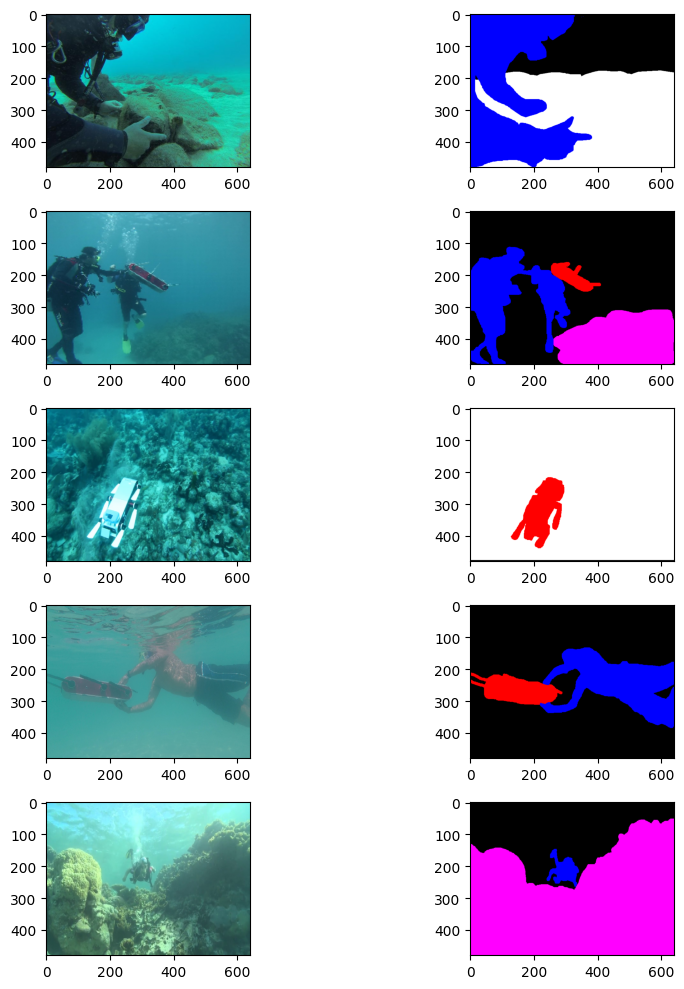

In [128]:
plot_images(train_images, train_masks)

In [4]:
seed = 411
batch_size = 16

image_data_generator = ImageDataGenerator(
    validation_split=0.2,
    rescale=1.0 / 255.0,
    rotation_range=45,
    zoom_range=0.2,
    shear_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='reflect',
)

mask_data_generator = ImageDataGenerator(
    validation_split=0.2,
    rescale=1.0 / 255.0,
    rotation_range=45,
    zoom_range=0.2,
    shear_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='reflect',
    # preprocessing_function=lambda x: rgb_to_label(x, label_colors),
)


In [42]:
class DataGenerator(Sequence):

    def __init__(self, image_paths, mask_paths, batch_size, img_height, img_width, shuffle=True, augmentation=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.batch_size = batch_size
        self.img_height = img_height
        self.img_width = img_width
        self.shuffle = shuffle
        self.augmentation = augmentation
        self.on_epoch_end()

    def __len__(self):
        return len(self.image_paths) // self.batch_size

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]

        image_paths_temp = [self.image_paths[k] for k in indexes]
        mask_paths_temp = [self.mask_paths[k] for k in indexes]

        images, masks = self.__data_generation(image_paths_temp, mask_paths_temp)

        return images, masks

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.image_paths))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __data_generation(self, image_paths_temp, mask_paths_temp):
        # Initialize batch arrays
        images = []
        masks = []

        for img_path, mask_path in zip(image_paths_temp, mask_paths_temp):
            # Load images
            img = cv.imread(img_path, cv.IMREAD_COLOR)
            mask = cv.imread(mask_path, cv.IMREAD_COLOR)

            # Convert to RGB
            img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
            mask = cv.cvtColor(mask, cv.COLOR_BGR2RGB)

            # Resize
            img = cv.resize(img, (self.img_width, self.img_height), interpolation=cv.INTER_NEAREST)
            mask = cv.resize(mask, (self.img_width, self.img_height), interpolation=cv.INTER_NEAREST)

            # Augment
            if self.augmentation:
                augmented = self.augmentation(image=img, mask=mask)
                img = augmented['image']
                mask = augmented['mask']

            # Normalize
            img = img / 255.0
            mask = mask / 255.0

            # Add to batch
            images.append(img)
            masks.append(mask)

        return np.array(images), np.array(masks)


In [43]:
dataset_dir = "input/example"

image_dir = os.path.join(dataset_dir, "images")
mask_dir = os.path.join(dataset_dir, "masks")

image_paths = [os.path.join(image_dir, f) for f in os.listdir(image_dir)]
mask_paths = [os.path.join(mask_dir, f) for f in os.listdir(mask_dir)]

train_images, val_images, train_masks, val_masks = train_test_split(image_paths, mask_paths, test_size=0.2,
                                                                    random_state=411)

# Ensure the lists are sorted to match the corresponding image and mask
image_paths.sort()
mask_paths.sort()

# Parameters
batch_size = 4
img_height = 480
img_width = 640

data_augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=45, p=0.8, interpolation=cv.INTER_NEAREST, border_mode=cv.BORDER_REFLECT),
])

# Create data generator
train_generator = DataGenerator(train_images, train_masks, batch_size, img_height, img_width,
                                augmentation=data_augmentation)
val_generator = DataGenerator(val_images, val_masks, batch_size, img_height, img_width)


Generating data for 4 images


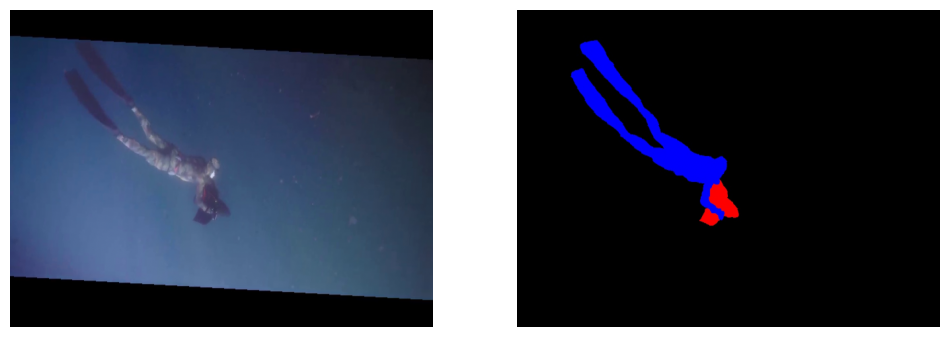

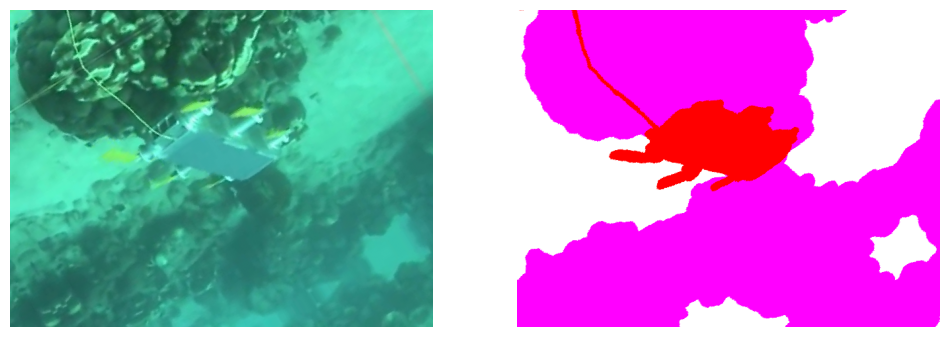

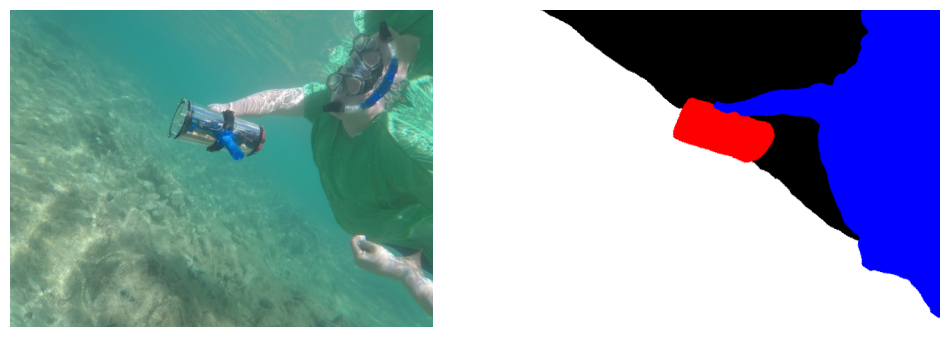

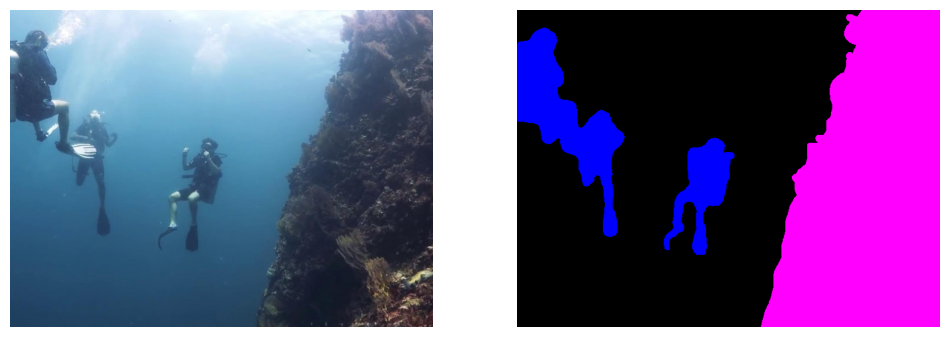

((4, 480, 640, 3), (4, 480, 640, 3), 1, 0)

In [46]:
batch = train_generator[0]
images, masks = batch

for img, mask in zip(images, masks):
    plt.figure(figsize=(12, 12))
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(mask)
    plt.axis('off')
    plt.show()

images.shape, masks.shape, len(train_generator), len(val_generator)